# BIT 2118 Scientific Computing Group Work
## Complete tasks 2-20

The supplied assignment brief requires all tasks, named inputs and operations, a changed input with explanation, interpretations of outputs/graphs, and a related real-world case documented with assumptions, inputs, outputs, and interpretation in an individual repository. The task directions are from the PDF; data and extensions below are illustrative. Run top to bottom in Anaconda Jupyter. NumPy, SciPy, and Matplotlib are required.

# BIT 2118 Scientific Computing  Task 2
## NumPy arrays and numerical computation

**Aim:** Use a NumPy array to summarize hourly weather-station readings and convert the readings from Celsius to Fahrenheit.

### Inputs and mathematical operations
- `temperatures_c`: 24 hourly temperature measurements in degrees Celsius.
- `np.mean`, `np.min`, and `np.max`: calculate the daily mean, minimum, and maximum.
- `F = 1.8C + 32`: convert each Celsius reading to Fahrenheit using NumPy vectorization.

### Interpretation
The summary describes the day's average and temperature range. The converted array gives the same readings on the Fahrenheit scale.

In [1]:
import numpy as np

# 24 hourly temperatures (degrees Celsius)
temperatures_c = np.array([
    18.5, 18.0, 17.8, 17.5, 17.9, 19.0,
    21.5, 23.8, 25.6, 27.1, 28.3, 29.0,
    29.4, 29.1, 28.5, 27.6, 26.2, 24.8,
    23.4, 22.1, 21.0, 20.2, 19.6, 19.0
])

mean_temp = np.mean(temperatures_c)
min_temp = np.min(temperatures_c)
max_temp = np.max(temperatures_c)
temperatures_f = 1.8 * temperatures_c + 32

print(f"Number of hourly readings: {temperatures_c.size}")
print(f"Daily mean temperature: {mean_temp:.2f} C")
print(f"Minimum temperature: {min_temp:.2f} C")
print(f"Maximum temperature: {max_temp:.2f} C")
print("First six Fahrenheit readings:", np.round(temperatures_f[:6], 2))

Number of hourly readings: 24
Daily mean temperature: 23.12 C
Minimum temperature: 17.50 C
Maximum temperature: 29.40 C
First six Fahrenheit readings: [65.3  64.4  64.04 63.5  64.22 66.2 ]


## Change one input and compare

To satisfy the parameter-change requirement, increase the noon reading (index 12) by 2 C. Then compare the daily mean. Since only one of 24 values changes, the daily mean rises by 2/24 = 0.0833 C; the maximum may also change if the noon reading becomes the day's highest value.

In [1]:
changed_temperatures_c = temperatures_c.copy()
changed_temperatures_c[12] += 2.0  # noon reading: 29.4 C -> 31.4 C

changed_mean = np.mean(changed_temperatures_c)
print(f"Original noon reading: {temperatures_c[12]:.1f} C")
print(f"Changed noon reading: {changed_temperatures_c[12]:.1f} C")
print(f"Original daily mean: {mean_temp:.4f} C")
print(f"Changed daily mean: {changed_mean:.4f} C")
print(f"Change in daily mean: {changed_mean - mean_temp:.4f} C")
print(f"Changed daily maximum: {np.max(changed_temperatures_c):.1f} C")

Original noon reading: 29.4 C
Changed noon reading: 31.4 C
Original daily mean: 23.1208 C
Changed daily mean: 23.2042 C
Change in daily mean: 0.0833 C
Changed daily maximum: 31.4 C


### Result interpretation
The noon measurement increased by 2 C, so the mean across 24 readings increased by about 0.0833 C. The maximum increased to 31.4 C. NumPy applies the conversion and summary calculations directly to the array, avoiding a manual loop.

### Task 2 related case: greenhouse monitoring
Assume the 24 hourly readings represent greenhouse temperatures and 28 C is an illustrative ventilation alert threshold. The input data are the temperature array and threshold; the operation selects hours at/above threshold. This is not agronomic advice.

In [1]:
threshold=28.0; flagged=np.flatnonzero(temperatures_c>=threshold); print('Threshold C:',threshold,'flagged zero-based hours:',flagged.tolist(),'count:',len(flagged)); print('Change threshold to 30 C; count:',int(np.sum(temperatures_c>=30)))

Threshold C: 28.0 flagged zero-based hours: [10, 11, 12, 13, 14] count: 5
Change threshold to 30 C; count: 0


## Task 3: Mathematical Functions and Vectorization

**Concept:** Vectorized NumPy expressions operate on whole arrays and can be compared with Python loops.

**Inputs and operation:** See code and printed labels. The code changes a parameter and reports the comparison.

**Related case, data, assumptions:** Simulated latency array (ms); divide by 1000 and square. A +20% input multiplies squares by 1.44. Related case: water flow rates in L/min converted to L/s. The same code prints case inputs and result where applicable.

**Interpretation:** The speed comparison shows how the same result can be expressed without an explicit Python loop; timing varies by computer and is not a universal benchmark. Squaring makes a 20% latency increase produce a 44% larger squared value.

In [1]:
rng=np.random.default_rng(42); x=rng.uniform(5,250,100000); import timeit
f=lambda:(x/1000)**2
def loop(): return [(v/1000)**2 for v in x]
a=timeit.timeit(loop,number=1); b=timeit.timeit(f,number=5)/5
print('100,000 simulated latencies; first squares:',f()[:5]); print('loop/vector seconds:',a,b,'speedup:',a/b)
print('Change: +20% latency gives squared ratio:',((1.2*x[0]/1000)**2)/f()[0])
q=np.array([12.,18.,25.])/60; print('Related flow L/s and squared index:',q,q*q)

100,000 simulated latencies; first squares: [0.03787665 0.01266192 0.04637842 0.03092504 0.00078812]
loop/vector seconds: 0.06134469999233261 0.0005057200090959668 speedup: 121.30170625835703
Change: +20% latency gives squared ratio: 1.4399999999999997
Related flow L/s and squared index: [0.2        0.3        0.41666667] [0.04       0.09       0.17361111]


## Task 4: Floating-Point Arithmetic and Numerical Errors

**Concept:** Binary floating point approximates most real values; compare with tolerance and quantify error.

**Inputs and operation:** See code and printed labels. The code changes a parameter and reports the comparison.

**Related case, data, assumptions:** Inputs: 0.1, 0.2, 0.3 and approximation 1.414 of sqrt(2). Change approximation to 1.41421356. Related case: currency as integer cents. The same code prints case inputs and result where applicable.

**Interpretation:** The exact comparison may be false even though the decimal values are mathematically equal; tolerance handles small representation error. The stable expression avoids cancellation for small x.

In [1]:
c=.1+.2; z=np.sqrt(2); print('sum/equality/isclose:',repr(c),c==.3,np.isclose(c,.3)); print('absolute/relative error:',abs(z-1.414),abs(z-1.414)/z); print('refined approximation error:',abs(z-1.41421356));
for x in [1e-4,1e-8,1e-12]: print(x,(np.sqrt(1+x)-1)/x,1/(np.sqrt(1+x)+1))
p=np.array([1999,250,1250]); tax=np.rint(p*.075).astype(int); print('Related cents prices/tax/total:',p,tax,p+tax)

sum/equality/isclose: 0.30000000000000004 False True
absolute/relative error: 0.00021356237309522186 0.00015101140222192286
refined approximation error: 2.3730950537981244e-09
0.0001 0.49998750062396624 0.49998750062496095
1e-08 0.4999999969612645 0.49999999875
1e-12 0.5000444502911705 0.499999999999875
Related cents prices/tax/total: [1999  250 1250] [150  19  94] [2149  269 1344]


## Task 5: Matrix Algebra and Matrix Operations

**Concept:** Matrix multiplication composes rotation and scaling; determinant gives area scale.

**Inputs and operation:** See code and printed labels. The code changes a parameter and reports the comparison.

**Related case, data, assumptions:** Inputs: unit square, 45 degree rotation, scales 2 and 1.5. Change x scale to 3. Related case: rotated ramp footprint. The same code prints case inputs and result where applicable.

**Interpretation:** The transformed vertices show the new shape and orientation. The determinant is the area multiplier; a nonzero determinant means the transform is invertible.

In [1]:
P=np.array([[0.,0],[1,0],[1,1],[0,1]]); a=np.deg2rad(45); Q=np.array([[np.cos(a),-np.sin(a)],[np.sin(a),np.cos(a)]]); M=Q@np.diag([2.,1.5]); print('transform:',M,'points:',P@M.T,'det:',np.linalg.det(M)); print('changed x scale determinant:',np.linalg.det(Q@np.diag([3.,1.5]))); ramp=np.array([[0.,0],[4,0],[4,1],[0,1]]); b=np.deg2rad(30); U=np.array([[np.cos(b),-np.sin(b)],[np.sin(b),np.cos(b)]]); print('Related rotated ramp:',ramp@U.T)

transform: [[ 1.41421356 -1.06066017]
 [ 1.41421356  1.06066017]] points: [[ 0.          0.        ]
 [ 1.41421356  1.41421356]
 [ 0.35355339  2.47487373]
 [-1.06066017  1.06066017]] det: 3.000000000000001
changed x scale determinant: 4.500000000000002
Related rotated ramp: [[ 0.          0.        ]
 [ 3.46410162  2.        ]
 [ 2.96410162  2.8660254 ]
 [-0.5         0.8660254 ]]


## Task 6: Solution of Systems of Linear Equations

**Concept:** Solve Ax=b for unknown quantities and verify by substitution and residual.

**Inputs and operation:** See code and printed labels. The code changes a parameter and reports the comparison.

**Related case, data, assumptions:** Inputs: CPU/RAM contributions and observed totals. Change CPU total 20 to 24. Related case: fertilizer blend. The same code prints case inputs and result where applicable.

**Interpretation:** The solved server quantities reproduce the measured CPU and memory totals. Near-zero residual confirms the linear system is satisfied.

In [1]:
A=np.array([[4.,2],[8,12]]); b=np.array([20.,72]); x=np.linalg.solve(A,b); print('A,b,solution,check,residual:',A,b,x,A@x,b-A@x); print('Changed CPU total solution:',np.linalg.solve(A,[24.,72.])); F=np.array([[10.,5],[2,8]]); y=np.linalg.solve(F,[40.,26]); print('Related fertilizer blend and nutrient check:',y,F@y)

A,b,solution,check,residual: [[ 4.  2.]
 [ 8. 12.]] [20. 72.] [3. 4.] [20. 72.] [0. 0.]
Changed CPU total solution: [4.5 3. ]
Related fertilizer blend and nutrient check: [2.71428571 2.57142857] [40. 26.]


## Task 7: Gaussian Elimination and LU Decomposition

**Concept:** LU factorization is reusable for multiple right-hand sides with the same coefficient matrix.

**Inputs and operation:** See code and printed labels. The code changes a parameter and reports the comparison.

**Related case, data, assumptions:** Fixed tridiagonal 3x3 matrix and multiple measurement vectors. Change first measurement 15 to 18. Related case: two-node circuit. The same code prints case inputs and result where applicable.

**Interpretation:** Small residuals show each LU solution fits its measured right-hand side. Reusing the factorization saves repeating elimination for each new observation.

In [1]:
A=np.array([[4.,-1,0],[-1,4,-1],[0,-1,3]]); f=lu_factor(A); bs=[[15.,10,10],[16.,11,9],[14.,12,11]]; print('LU reused; inputs RHS:',bs)
for b in bs:
 x=lu_solve(f,b); print('solution/residual:',x,np.linalg.norm(A@x-b))
print('changed RHS:',lu_solve(f,[18.,10,10])); G=np.array([[3.,-1],[-1,2.]]); g=lu_factor(G); print('Related circuit voltages:',[lu_solve(g,b) for b in ([5.,1.],[6.,1.])])

LU reused; inputs RHS: [[15.0, 10, 10], [16.0, 11, 9], [14.0, 12, 11]]
solution/residual: [5. 5. 5.] 0.0
solution/residual: [5.31707317 5.26829268 4.75609756] 1.7763568394002505e-15
solution/residual: [4.90243902 5.6097561  5.53658537] 0.0
changed RHS: [5.80487805 5.2195122  5.07317073]
Related circuit voltages: [array([2.2, 1.6]), array([2.6, 1.8])]


## Task 8: Iterative Methods for Linear Systems

**Concept:** Jacobi updates all values from old iterate; Gauss-Seidel uses new values immediately.

**Inputs and operation:** See code and printed labels. The code changes a parameter and reports the comparison.

**Related case, data, assumptions:** Five-node steady temperature grid, boundaries 100/20, tolerance 1e-8; change tolerance to 1e-4. Related room wall. The same code prints case inputs and result where applicable.

**Interpretation:** The temperature estimates approach the direct solution. The semilog graph displays shrinking update sizes; Gauss-Seidel generally reaches the tolerance in fewer iterations here.

Jacobi/GS/direct and iterations: [86.66666665 73.33333331 59.99999997 46.66666664 33.33333332] 150 [86.66666665 73.3333333  59.99999997 46.66666665 33.33333332] 75 [86.66666667 73.33333333 60.         46.66666667 33.33333333]
changed tolerance iterations: 86
Related 80/20 wall temperatures: [69.99999998 59.99999998 49.99999998 39.99999998 29.99999999]


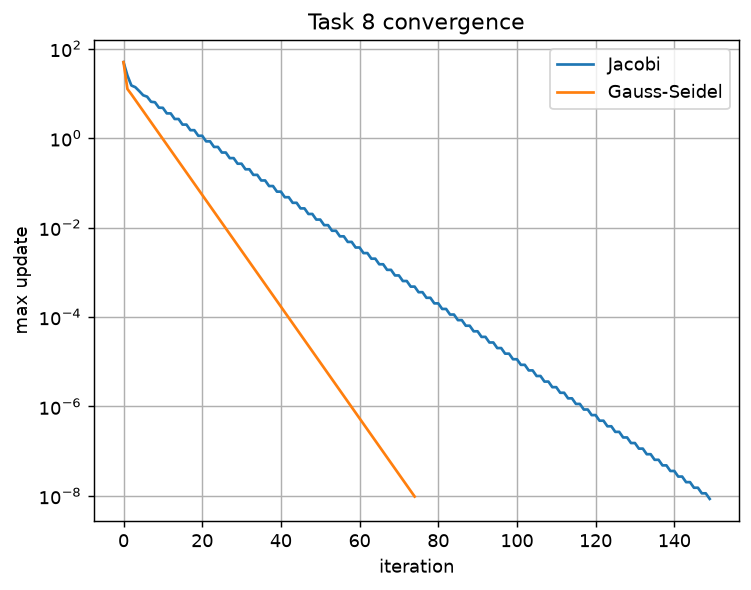

In [1]:
A=2*np.eye(5)-np.eye(5,k=1)-np.eye(5,k=-1); b=np.array([100.,0,0,0,20.])
def it(A,b,gs,tol):
 x=np.zeros(len(b)); e=[]
 for _ in range(500):
  old=x.copy()
  if not gs: x=(b-(A-np.diag(np.diag(A)))@old)/np.diag(A)
  else:
   for i in range(len(b)): x[i]=(b[i]-A[i,:i]@x[:i]-A[i,i+1:]@old[i+1:])/A[i,i]
  e.append(max(abs(x-old)))
  if e[-1]<tol: break
 return x,e
x,e=it(A,b,False,1e-8); y,g=it(A,b,True,1e-8); print('Jacobi/GS/direct and iterations:',x,len(e),y,len(g),np.linalg.solve(A,b)); print('changed tolerance iterations:',len(it(A,b,False,1e-4)[1])); plt.semilogy(e,label='Jacobi'); plt.semilogy(g,label='Gauss-Seidel'); plt.xlabel('iteration'); plt.ylabel('max update'); plt.title('Task 8 convergence'); plt.legend(); plt.grid(); print('Related 80/20 wall temperatures:',it(A,[80,0,0,0,20],True,1e-8)[0])

## Task 9: Eigenvalues and Eigenvectors

**Concept:** The dominant eigenvector of an adjacency matrix gives relative eigenvector centrality scores.

**Inputs and operation:** See code and printed labels. The code changes a parameter and reports the comparison.

**Related case, data, assumptions:** Four-node undirected graph; change by adding edge A-D. Related case: road network. The same code prints case inputs and result where applicable.

**Interpretation:** Scores sum to one and rank nodes by connectivity to other well-connected nodes. Adding an edge shifts relative importance; this score is not a traffic forecast.

In [1]:
A=np.array([[0,1,1,0],[1,0,1,1],[1,1,0,1],[0,1,1,0.]],float); w,V=np.linalg.eig(A); k=np.argmax(w.real); s=abs(V[:,k].real); s/=s.sum(); print('dominant eigenvalue, centrality:',w[k],s); A[0,3]=A[3,0]=1; w,V=np.linalg.eig(A); s2=abs(V[:,np.argmax(w.real)].real); s2/=s2.sum(); print('changed graph centrality:',s2,'residual:',np.linalg.norm(A@V[:,np.argmax(w.real)].real-w.max().real*V[:,np.argmax(w.real)].real)); print('Related road importance for nodes A-D:',s2)

dominant eigenvalue, centrality: 2.5615528128088303 [0.21922359 0.28077641 0.28077641 0.21922359]
changed graph centrality: [0.25 0.25 0.25 0.25] residual: 8.005932084973442e-16
Related road importance for nodes A-D: [0.25 0.25 0.25 0.25]


## Task 10: Root Finding: Bisection and Fixed-Point Methods

**Concept:** Bisection halves a sign-changing bracket; fixed-point iteration repeatedly applies T=g(T).

**Inputs and operation:** See code and printed labels. The code changes a parameter and reports the comparison.

**Related case, data, assumptions:** Heat-balance f(T)=0, bracket 20-40 C and initial fixed-point 30 C; vary bisection tolerance. Related tank equilibrium. The same code prints case inputs and result where applicable.

**Interpretation:** Both methods find the heat-balance zero. The plotted curve crossing at zero is the equilibrium; a looser tolerance reduces work but permits a less precise estimate.

bisection/fixed point/iterations: 27.525210819221684 27.52521081928387 38 13
changed tolerance iterations: 18
Related tank level: 3.9154853193178845


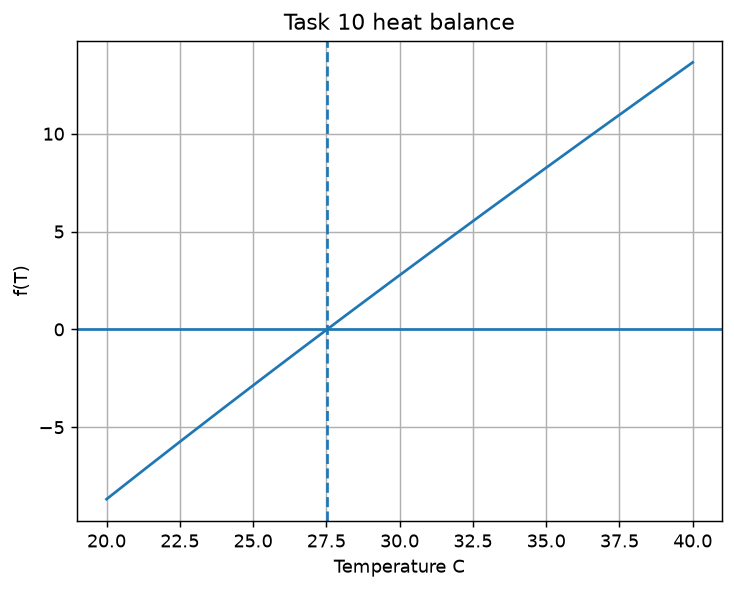

In [1]:
f=lambda T:T-25-10*np.exp(-T/20); s=root_scalar(f,bracket=[20,40],method='bisect',xtol=1e-10); T=30.; hist=[T]
for _ in range(100):
 q=25+10*np.exp(-T/20); hist.append(q)
 if abs(q-T)<1e-10: break
 T=q
print('bisection/fixed point/iterations:',s.root,hist[-1],s.iterations,len(hist)-1); print('changed tolerance iterations:',root_scalar(f,bracket=[20,40],method='bisect',xtol=1e-4).iterations); t=np.linspace(20,40,200); plt.plot(t,f(t)); plt.axhline(0); plt.axvline(s.root,ls='--'); plt.xlabel('Temperature C'); plt.ylabel('f(T)'); plt.title('Task 10 heat balance'); plt.grid(); print('Related tank level:',root_scalar(lambda h:h+4*np.exp(-h/3)-5,bracket=[1,8]).root)

## Task 11: Root Finding: Newton-Raphson and Secant Methods

**Concept:** Newton uses an analytic derivative; secant estimates a slope from recent points.

**Inputs and operation:** See code and printed labels. The code changes a parameter and reports the comparison.

**Related case, data, assumptions:** Cash flows -10000 then 3000,3500,4000,2500; solve NPV=0. Change final inflow +500. Related equipment investment. The same code prints case inputs and result where applicable.

**Interpretation:** The two methods agree on the rate that makes net present value zero. Increasing the final cash inflow raises the rate of return in this example.

In [1]:
c=np.array([-10000.,3000,3500,4000,2500]); f=lambda r:sum(v/(1+r)**i for i,v in enumerate(c)); df=lambda r:sum(-i*v/(1+r)**(i+1) for i,v in enumerate(c) if i); n=root_scalar(f,fprime=df,x0=.1,method='newton'); s=root_scalar(f,x0=.05,x1=.2,method='secant'); print('Newton/secant IRR, NPV residual:',n.root,s.root,f(n.root)); c[-1]+=500; f2=lambda r:sum(v/(1+r)**i for i,v in enumerate(c)); df2=lambda r:sum(-i*v/(1+r)**(i+1) for i,v in enumerate(c) if i); print('changed final inflow IRR:',root_scalar(f2,fprime=df2,x0=.1,method='newton').root); d=[-5000,1800,1900,2100]; print('Related equipment break-even rate:',root_scalar(lambda r:sum(v/(1+r)**i for i,v in enumerate(d)),x0=.1,x1=.2,method='secant').root)

Newton/secant IRR, NPV residual: 0.11542460676490277 0.11542460676490295 2.2737367544323206e-12
changed final inflow IRR: 0.13038164637097913
Related equipment break-even rate: 0.07596221004350667


## Task 12: Polynomial and Nonlinear Equation Solving

**Concept:** A nonlinear solver seeks unknowns making all residuals close to zero; initial guesses can select different roots.

**Inputs and operation:** See code and printed labels. The code changes a parameter and reports the comparison.

**Related case, data, assumptions:** Circle x^2+y^2=4 and parabola y=x^2-1; change initial guess. Related geometry intersection. The same code prints case inputs and result where applicable.

**Interpretation:** The returned coordinates satisfy both circle and parabola equations when residuals are close to zero. Different starting points can find different intersections.

In [1]:
def f(z):
 x,y=z; return [x*x+y*y-4,y-(x*x-1)]
for g in ([1.,1.],[-1.,1.]):
 s=root(f,g); print('input guess, root, residual, success:',g,s.x,f(s.x),s.success)
print('changed guess [1,2]:',root(f,[1,2]).x)
def q(z):
 x,y=z; return [x*x+y*y-9,y-(x*x-2)]
s=root(q,[1,1]); print('Related circle-channel intersection:',s.x,q(s.x))

input guess, root, residual, success: [1.0, 1.0] [1.51748991 1.30277564] [np.float64(-2.4780177909633494e-13), np.float64(-2.4158453015843406e-13)] True
input guess, root, residual, success: [-1.0, 1.0] [-1.51748991  1.30277564] [np.float64(-2.4780177909633494e-13), np.float64(-2.4158453015843406e-13)] True
changed guess [1,2]: [1.51748991 1.30277564]
Related circle-channel intersection: [2.04757965 2.1925824 ] [np.float64(3.836930773104541e-13), np.float64(2.9531932455029164e-13)]


## Task 13: Interpolation

**Concept:** Linear and cubic spline interpolation estimate values between measured samples.

**Inputs and operation:** See code and printed labels. The code changes a parameter and reports the comparison.

**Related case, data, assumptions:** Hourly temperature observations, estimate 10:30; change 10:00 reading +1C. Related missing rainfall estimate. The same code prints case inputs and result where applicable.

**Interpretation:** Both interpolants estimate the missing between-hour value. The line is piecewise linear; the spline is smoother, but neither should be treated as a forecast beyond observed times.

10:30 linear/cubic C: 23.25 23.36328125
changed 10:00 +1 C; estimates: 23.75 23.942522321428573
Related rainfall estimate at 10:30: 1.6 mm/h


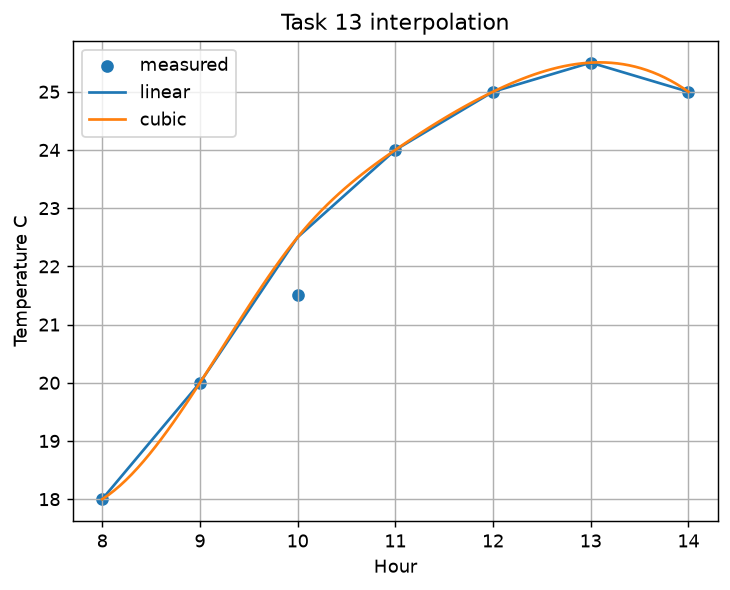

In [1]:
h=np.arange(8.,15.); y=np.array([18.,20.,22.5,24,25,25.5,25]); f=interp1d(h,y); c=CubicSpline(h,y); print('10:30 linear/cubic C:',float(f(10.5)),float(c(10.5))); y[2]+=1; print('changed 10:00 +1 C; estimates:',float(interp1d(h,y)(10.5)),float(CubicSpline(h,y)(10.5))); tt=np.linspace(8,14,100); plt.scatter(h,np.array([18,20,21.5,24,25,25.5,25]),label='measured'); plt.plot(tt,f(tt),label='linear'); plt.plot(tt,c(tt),label='cubic'); plt.title('Task 13 interpolation'); plt.xlabel('Hour'); plt.ylabel('Temperature C'); plt.legend(); plt.grid(); print('Related rainfall estimate at 10:30:',float(interp1d([10,11,12],[1.2,2,1.6])(10.5)),'mm/h')

## Task 14: Curve Fitting and Approximation

**Concept:** Least squares fits model parameters to minimize squared residuals; use RMSE and prediction cautiously.

**Inputs and operation:** See code and printed labels. The code changes a parameter and reports the comparison.

**Related case, data, assumptions:** Concurrent users and measured server latency fit quadratic; change highest observed latency +50ms. Related production cost curve. The same code prints case inputs and result where applicable.

**Interpretation:** The fitted curve summarizes the observed latency trend; RMSE is the typical scale of residual errors. The estimate beyond the measured user loads is extrapolation and is less certain.

coefficients/RMSE/prediction400: [ 2.16666667e-03 -1.34523810e-01  8.50000000e+01] 1.5496323900259958 377.8571428571587
changed last observation +50; prediction400: 442.14285714289304
Related production cost at 50 units: 681.2500000000001


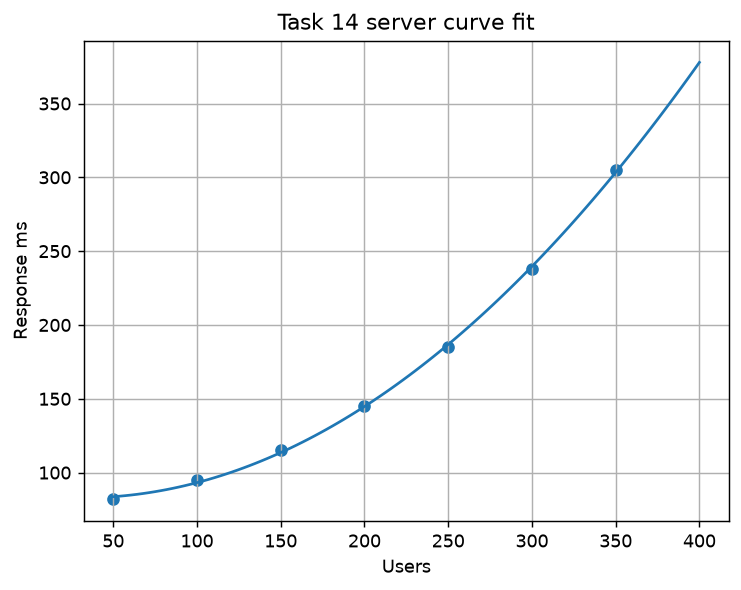

In [1]:
x=np.array([50,100,150,200,250,300,350.]); y=np.array([82,95,115,145,185,238,305.]); m=lambda x,a,b,c:a*x*x+b*x+c; p,_=curve_fit(m,x,y); print('coefficients/RMSE/prediction400:',p,np.sqrt(np.mean((y-m(x,*p))**2)),m(400,*p)); y[-1]+=50; p2,_=curve_fit(m,x,y); print('changed last observation +50; prediction400:',m(400,*p2)); xx=np.linspace(50,400,100); plt.scatter(x,[82,95,115,145,185,238,305]); plt.plot(xx,m(xx,*p)); plt.title('Task 14 server curve fit'); plt.xlabel('Users'); plt.ylabel('Response ms'); plt.grid(); u=np.array([10.,20,30,40]); z=np.array([120.,205,325,485]); q,_=curve_fit(m,u,z); print('Related production cost at 50 units:',m(50,*q))

## Task 15: Numerical Differentiation

**Concept:** Finite differences approximate derivatives; central differences use neighboring samples.

**Inputs and operation:** See code and printed labels. The code changes a parameter and reports the comparison.

**Related case, data, assumptions:** GPS positions each second estimate speed; change position at t=3 by +2m. Related walking speed. The same code prints case inputs and result where applicable.

**Interpretation:** The speed estimates approximate position change per second. Central differences use neighboring samples; noisy position data can make derivative estimates fluctuate.

GPS position inputs: [ 0.   4.8 10.2 16.1 22.7 30.  38. ] estimated speed: [4.8  5.1  5.65 6.25 6.95 7.65 8.  ]
changed middle position +2m; speed: [4.8  5.1  6.65 6.25 5.95 7.65 8.  ]
Related walking speed: [1.4   1.475 1.625 1.7  ]


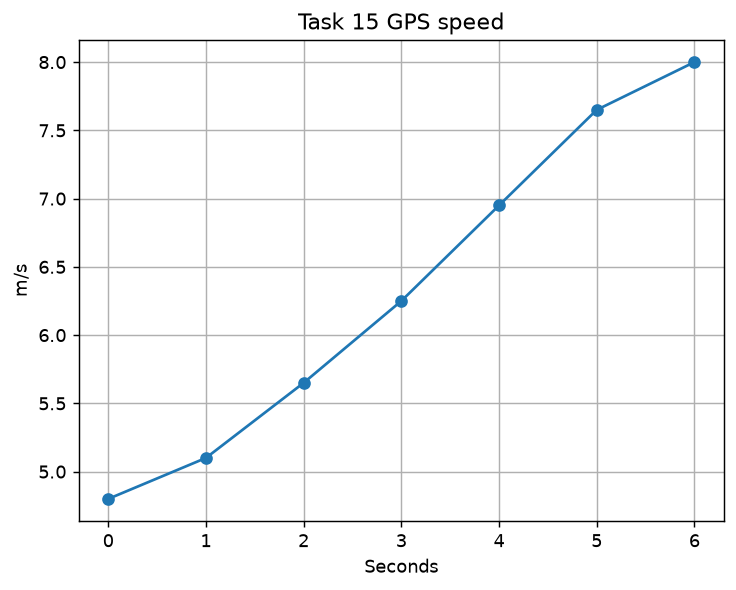

In [1]:
t=np.arange(7.); x=np.array([0.,4.8,10.2,16.1,22.7,30,38]); v=np.gradient(x,t); print('GPS position inputs:',x,'estimated speed:',v); x[3]+=2; print('changed middle position +2m; speed:',np.gradient(x,t)); plt.plot(t,v,'o-'); plt.title('Task 15 GPS speed'); plt.xlabel('Seconds'); plt.ylabel('m/s'); plt.grid(); print('Related walking speed:',np.gradient([0.,2.8,5.9,9.3],[0.,2.,4.,6.]))

## Task 16: Numerical Integration

**Concept:** Integrating power over time yields energy; compare trapezoidal and Simpson estimates.

**Inputs and operation:** See code and printed labels. The code changes a parameter and reports the comparison.

**Related case, data, assumptions:** Power readings in kW every two hours; change all by +10%. Related trip distance from speed. The same code prints case inputs and result where applicable.

**Interpretation:** The integrals estimate accumulated energy in kWh. Their difference reflects alternative approximations between sparse power samples; the related speed integral gives distance.

In [1]:
t=np.arange(0,13,2,dtype=float); p=np.array([.8,1,1.4,1.8,1.6,1.2,.9]); a=np.trapezoid(p,t); b=simpson(p,x=t); print('inputs power kW:',p,'trap/Simpson kWh and difference:',a,b,abs(a-b)); print('changed readings +10%, Simpson energy:',simpson(1.1*p,x=t)); print('Related speed-integrated trip km:',simpson([0,30,50,45,20],x=[0,.5,1,1.5,2]))

inputs power kW: [0.8 1.  1.4 1.8 1.6 1.2 0.9] trap/Simpson kWh and difference: 15.700000000000001 15.799999999999999 0.09999999999999787
changed readings +10%, Simpson energy: 17.380000000000003
Related speed-integrated trip km: 70.0


## Task 17: Ordinary Differential Equations: Euler Method

**Concept:** Euler updates T by T_next=T+h f(T); smaller steps usually improve accuracy at more computation.

**Inputs and operation:** See code and printed labels. The code changes a parameter and reports the comparison.

**Related case, data, assumptions:** Newton cooling T0=90, ambient=25, k=.12/min; change step 1 to .5 min. Related drink cooling. The same code prints case inputs and result where applicable.

**Interpretation:** The plotted temperature falls toward ambient temperature. Reducing Euler step size improves the numerical estimate here, at the cost of more steps.

h, Euler final, exact, error: 1.0 26.40408539246636 26.776041959074018 0.37195656660765763
h, Euler final, exact, error: 0.5 26.587027939803267 26.776041959074018 0.18901401927075057
changed initial temperature to 100; final: 26.62009852976887
Related illustrative drink final temp: 24.24805280290183


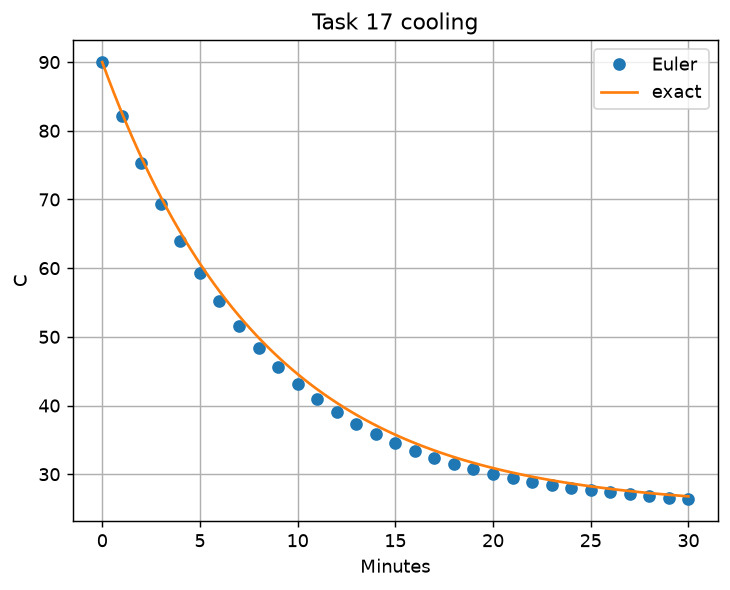

In [1]:
ambient=25.; k=.12; end=30.; exact=ambient+65*np.exp(-k*end)
def euler(h,T0=90.):
 t=np.arange(0,end+h/2,h); z=np.zeros(len(t)); z[0]=T0
 for i in range(len(t)-1): z[i+1]=z[i]-h*k*(z[i]-ambient)
 return t,z
for h in [1.,.5]:
 t,z=euler(h); print('h, Euler final, exact, error:',h,z[-1],exact,abs(z[-1]-exact))
t,z=euler(1,100); print('changed initial temperature to 100; final:',z[-1]); t,z=euler(1); plt.plot(t,z,'o',label='Euler'); q=np.linspace(0,30,100); plt.plot(q,ambient+65*np.exp(-k*q),label='exact'); plt.title('Task 17 cooling'); plt.xlabel('Minutes'); plt.ylabel('C'); plt.legend(); plt.grid(); print('Related illustrative drink final temp:',22+58*.85**20)

## Task 18: Numerical Solution of ODEs Using SciPy

**Concept:** solve_ivp numerically integrates ODEs with adaptive steps; compare an ideal RC charging solution to its exact curve.

**Inputs and operation:** See code and printed labels. The code changes a parameter and reports the comparison.

**Related case, data, assumptions:** Vs=5V, R=1kohm, C=1mF; double capacitance. Related RC discharge. The same code prints case inputs and result where applicable.

**Interpretation:** The SciPy solution tracks the exact RC charging curve and approaches supply voltage. Doubling capacitance increases the time constant and slows charging.

inputs Vs/R/C/V0: 5/1000/.001/0; success, V(5), max error: True 4.966310264134187 9.281748702960613e-10
changed capacitance x2; V(5): 4.589194330761201
Related RC discharge voltage at 5s: 0.9860720898632519


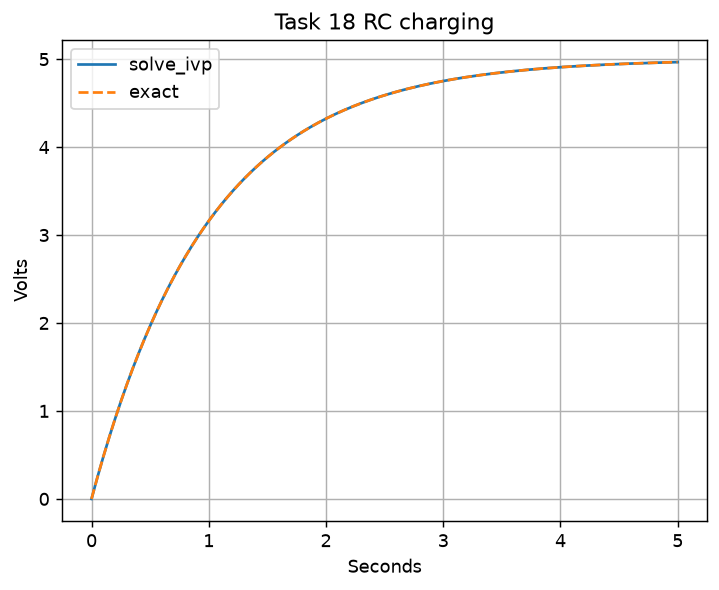

In [1]:
Vs=5.; tau=1000*.001; t=np.linspace(0,5,200); s=solve_ivp(lambda t,V:[(Vs-V[0])/tau],(0,5),[0.],t_eval=t,rtol=1e-9,atol=1e-11); exact=Vs*(1-np.exp(-t/tau)); print('inputs Vs/R/C/V0: 5/1000/.001/0; success, V(5), max error:',s.success,s.y[0,-1],max(abs(s.y[0]-exact))); slow=solve_ivp(lambda t,V:[(Vs-V[0])/(2*tau)],(0,5),[0.],t_eval=[5]); print('changed capacitance x2; V(5):',slow.y[0,-1]); plt.plot(t,s.y[0],label='solve_ivp'); plt.plot(t,exact,'--',label='exact'); plt.title('Task 18 RC charging'); plt.xlabel('Seconds'); plt.ylabel('Volts'); plt.legend(); plt.grid(); d=solve_ivp(lambda t,V:[-V[0]/2],(0,5),[12.],t_eval=[5]); print('Related RC discharge voltage at 5s:',d.y[0,-1])

## Task 19: Numerical Optimization

**Concept:** Minimize linear cost with capacity and nonnegative constraints; enumerate integer solutions for deployable counts.

**Inputs and operation:** See code and printed labels. The code changes a parameter and reports the comparison.

**Related case, data, assumptions:** Costs A/B 12/18; capacities 100/170; minimum 1000. Change A cost to 14. Related solar capacity plan. The same code prints case inputs and result where applicable.

**Interpretation:** The continuous optimizer finds the lowest modeled cost under the capacity constraint. Whole-unit enumeration gives a feasible implementable plan, which may differ from the fractional optimum.

In [1]:
cost=lambda z:12*z[0]+18*z[1]; cap=lambda z:100*z[0]+170*z[1]-1000; r=minimize(cost,[5,3],method='SLSQP',bounds=[(0,None)]*2,constraints={'type':'ineq','fun':cap}); print('continuous success/allocation/capacity/cost:',r.success,r.x,100*r.x[0]+170*r.x[1],r.fun); best=min((12*a+18*b,a,b,100*a+170*b) for a in range(20) for b in range(20) if 100*a+170*b>=1000); print('best integer cost,A,B,capacity:',best); r2=minimize(lambda z:14*z[0]+18*z[1],[5,3],method='SLSQP',bounds=[(0,None)]*2,constraints={'type':'ineq','fun':cap}); print('changed A cost 14; allocation/cost:',r2.x,r2.fun); print('Related solar integer plan cost,A,B,capacity:',min((8*a+13*b,a,b,120*a+210*b) for a in range(20) for b in range(20) if 120*a+210*b>=500))

continuous success/allocation/capacity/cost: True [0.         5.88235294] 999.9999999999525 105.88235294117145
best integer cost,A,B,capacity: (108, 0, 6, 1020)
changed A cost 14; allocation/cost: [1.88782323e-12 5.88235294e+00] 105.8823529412225
Related solar integer plan cost,A,B,capacity: (34, 1, 2, 540)


## Task 20: Random Numbers and Monte Carlo Methods

**Concept:** Monte Carlo estimates probability by repeated sampling; reproducible random seed and sample count matter.

**Inputs and operation:** See code and printed labels. The code changes a parameter and reports the comparison.

**Related case, data, assumptions:** Normal demand mean 850/sd 120, capacity 1000, N=100,000; increase N to 400,000. Related inventory stockout risk. The same code prints case inputs and result where applicable.

**Interpretation:** The probability estimate is the fraction of simulated demands above capacity. The convergence plot is noisy at first and settles as sample size grows; it remains a statistical estimate.

inputs mean/sd/capacity/N/seed: 850/120/1000/100000/42
overload estimate/count: 0.10616 10616
changed N to 400000: 0.10579
Related inventory stockout probability: 0.156425


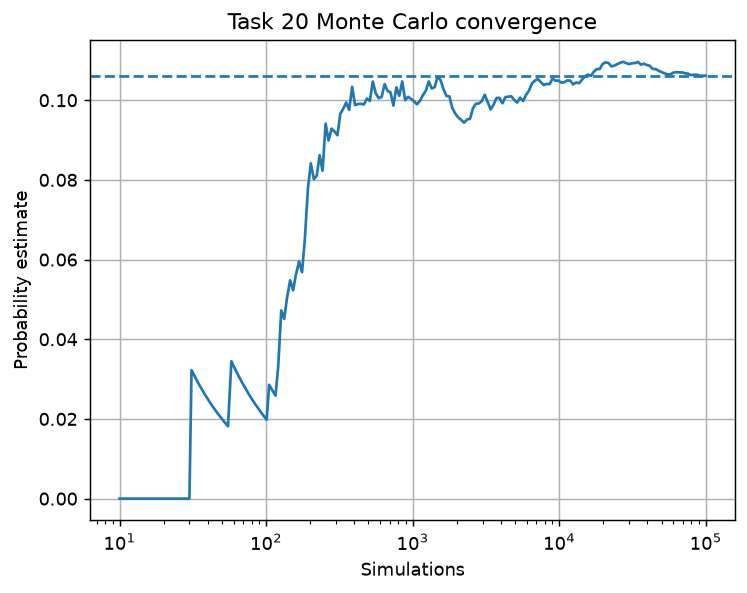

In [1]:
rng=np.random.default_rng(42); N=100000; d=rng.normal(850,120,N); bad=d>1000; p=bad.mean(); print('inputs mean/sd/capacity/N/seed: 850/120/1000/100000/42'); print('overload estimate/count:',p,bad.sum()); ix=np.unique(np.logspace(1,np.log10(N),200).astype(int))-1; run=np.cumsum(bad)/np.arange(1,N+1); plt.semilogx(ix+1,run[ix]); plt.axhline(p,ls='--'); plt.title('Task 20 Monte Carlo convergence'); plt.xlabel('Simulations'); plt.ylabel('Probability estimate'); plt.grid(); print('changed N to 400000:',np.mean(rng.normal(850,120,400000)>1000)); print('Related inventory stockout probability:',np.mean(rng.normal(620,80,200000)>700))

## Overall interpretation
NumPy handles vectors, matrices and floating-point calculations; SciPy provides algorithms for systems, roots, interpolation, curve fitting, integration, ODEs and optimization; Matplotlib makes behavior and convergence visible. Estimates depend on the stated synthetic data and assumptions. Check solver success/residuals, avoid over-interpreting extrapolation, and account for Monte Carlo sampling uncertainty.